In [1]:
# ---------- CELL 0: locate the project (same in every notebook) ----------
import os, sys
from pathlib import Path

def find_root(marker="PROJECT_ROOT.marker"):
    here = Path.cwd().resolve()                      # start where this notebook runs
    for folder in [here, *here.parents]:             # go UP one level at a time
        if (folder / marker).exists():
            return folder
    if "google.colab" in sys.modules:                # Colab: look inside Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        for pattern in (marker, f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}"):
            hits = sorted(Path("/content/drive/MyDrive").glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("PROJECT_ROOT.marker not found - finish Day 1 first.")

ROOT = find_root()
os.chdir(ROOT / "notebooks")
RAW, CLEAN = ROOT/"data"/"raw", ROOT/"data"/"clean"
FEATURES, MODEL_OUT = ROOT/"data"/"features", ROOT/"data"/"model_outputs"
SQL_EXPORTS, BI_READY = ROOT/"data"/"sql_exports", ROOT/"data"/"bi_ready"
MODELS, REPORTS, DOCS = ROOT/"models", ROOT/"reports", ROOT/"docs"
FIGURES = REPORTS/"figures"
sys.path.append(str(ROOT/"src"))
print("Project root:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/Internmo/netflix_churn_project


In [2]:
# ---------- CELL 1: load ----------
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

predictions = pd.read_csv(MODEL_OUT / "churn_predictions.csv")
segments    = pd.read_csv(MODEL_OUT / "customer_segments.csv")[["customer_id", "segment_name", "plan_price"]]
test_pred   = pd.read_csv(MODEL_OUT / "churn_test_predictions.csv")
train_table = pd.read_csv(FEATURES / "customer_features_train.csv")
dates       = pd.read_csv(FEATURES / "snapshot_dates.csv", parse_dates=["date"]).set_index("name")["date"]
metrics     = pd.read_csv(REPORTS / "churn_model_metrics.csv")

TRAIN_CUTOFF, AS_OF = dates["train_cutoff"], dates["scoring_date"]
HORIZON_MONTHS = (AS_OF - TRAIN_CUTOFF).days / 30.44           # the window the churn probability refers to
print(f"The churn probability describes churn over about {HORIZON_MONTHS:.1f} months ({TRAIN_CUTOFF.date()} -> {AS_OF.date()})")

The churn probability describes churn over about 8.9 months (2025-10-02 -> 2026-06-30)


In [3]:
# ---------- CELL 2: expected value ----------
value = predictions.merge(segments, on="customer_id")
assert len(value) == len(predictions) and value["plan_price"].notna().all()

p = value["churn_probability"].clip(0.001, 0.99)
value["monthly_churn_hazard"] = 1 - (1 - p) ** (1 / HORIZON_MONTHS)

# sum of (1 - hazard)^m for m = 0..11  (closed form of a geometric series)
survive = 1 - value["monthly_churn_hazard"]
value["expected_months_paid_12m"] = (1 - survive ** 12) / value["monthly_churn_hazard"]

value["max_value_12m"]       = (value["plan_price"] * 12).round(2)
value["expected_value_12m"]  = (value["plan_price"] * value["expected_months_paid_12m"]).round(2)
value["value_at_risk_12m"]   = (value["max_value_12m"] - value["expected_value_12m"]).round(2)

# sanity checks: values must lie between 0 and the maximum, and risky customers must be worth less
assert (value["expected_value_12m"] <= value["max_value_12m"]).all() and (value["expected_value_12m"] > 0).all()
print(value[["churn_probability", "monthly_churn_hazard", "expected_months_paid_12m"]].describe().round(3))
print("\nTotal 12-month revenue if nobody churned :", round(value["max_value_12m"].sum()))
print("Expected 12-month revenue                :", round(value["expected_value_12m"].sum()))
print("Value at risk                            :", round(value["value_at_risk_12m"].sum()),
      f"({100 * value['value_at_risk_12m'].sum() / value['max_value_12m'].sum():.1f}%)")

       churn_probability  monthly_churn_hazard  expected_months_paid_12m
count           6009.000              6009.000                  6009.000
mean               0.246                 0.031                    10.139
std                0.053                 0.008                     0.414
min                0.127                 0.015                     7.809
25%                0.221                 0.028                     9.992
50%                0.233                 0.029                    10.242
75%                0.265                 0.034                    10.331
max                0.535                 0.082                    11.050

Total 12-month revenue if nobody churned : 976379
Expected 12-month revenue                : 825044
Value at risk                            : 151335 (15.5%)


In [4]:
# ---------- CELL 3: save the value table ----------
columns = ["customer_id", "segment_name", "plan_price", "churn_probability", "risk_tier", "risk_flags",
           "expected_months_paid_12m", "max_value_12m", "expected_value_12m", "value_at_risk_12m"]
value = value.sort_values("value_at_risk_12m", ascending=False)
value[columns].round(3).to_csv(MODEL_OUT / "customer_value.csv", index=False)
value[columns].head(20)

,customer_id,segment_name,plan_price,churn_probability,risk_tier,risk_flags,expected_months_paid_12m,max_value_12m,expected_value_12m,value_at_risk_12m
0,CUST005732,New & Highly Engaged,22.99,0.5353,High,"Low support CSAT, Negative feedback, Auto-rene...",7.808562,275.88,179.52,96.36
1,CUST005273,New & Highly Engaged,22.99,0.5205,High,"2+ support tickets, Under 1 year tenure",7.933628,275.88,182.39,93.49
6,CUST005435,Payment Trouble,22.99,0.4964,High,"Failed payment (90d), 2+ support tickets, Auto...",8.135573,275.88,187.04,88.84
11,CUST005811,Payment Trouble,22.99,0.4816,High,"Failed payment (90d), 2+ support tickets, Nega...",8.258603,275.88,189.87,86.01
22,CUST001601,Payment Trouble,22.99,0.4571,High,"Failed payment (90d), Low support CSAT",8.460730,275.88,194.51,81.37
30,CUST003252,New & Highly Engaged,22.99,0.4475,High,"2+ support tickets, Auto-renew off, Under 1 ye...",8.539434,275.88,196.32,79.56
35,CUST007886,Payment Trouble,22.99,0.4383,High,"2+ support tickets, Low support CSAT, Auto-ren...",8.614609,275.88,198.05,77.83
40,CUST002365,High-Value Loyalists,22.99,0.4345,High,"Low support CSAT, Auto-renew off",8.645589,275.88,198.76,77.12
53,CUST002456,Payment Trouble,22.99,0.4253,High,"Failed payment (90d), Under 1 year tenure",8.720429,275.88,200.48,75.40
51,CUST001125,Payment Trouble,22.99,0.4253,High,"Failed payment (90d), Under 1 year tenure",8.720429,275.88,200.48,75.40


Test AUC 0.568  (95% interval 0.535 to 0.602)


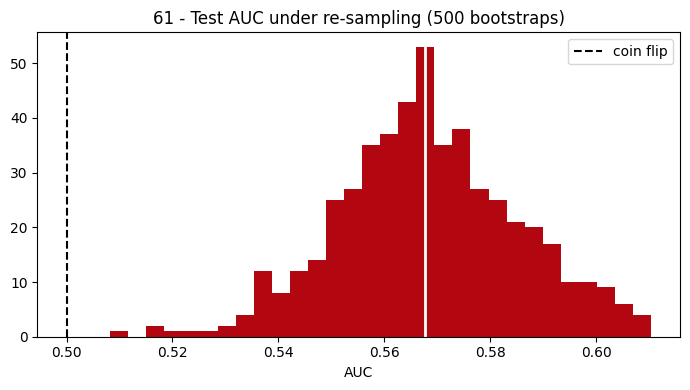

In [5]:
# ---------- CELL 4: bootstrap confidence interval ----------
from sklearn.metrics import roc_auc_score, average_precision_score

y_true = test_pred["churned"].to_numpy()
score = test_pred["churn_probability"].to_numpy()
rng = np.random.default_rng(42)

boot = []
for _ in range(500):
    idx = rng.integers(0, len(y_true), len(y_true))
    if y_true[idx].min() == y_true[idx].max():
        continue
    boot.append(roc_auc_score(y_true[idx], score[idx]))
boot = np.array(boot)
test_auc = roc_auc_score(y_true, score)
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f"Test AUC {test_auc:.3f}  (95% interval {ci_low:.3f} to {ci_high:.3f})")

plt.figure(figsize=(7, 4))
plt.hist(boot, bins=30, color="#b20710")
plt.axvline(0.5, color="black", linestyle="--", label="coin flip")
plt.axvline(test_auc, color="white", linestyle="-", linewidth=2)
plt.title("61 - Test AUC under re-sampling (500 bootstraps)"); plt.xlabel("AUC"); plt.legend()
plt.tight_layout(); plt.savefig(FIGURES / "61_auc_bootstrap.png", bbox_inches="tight"); plt.show()

     customers  mean_predicted  actual_churn_rate
bin                                              
1          146           0.179              0.137
2          146           0.216              0.233
3          145           0.221              0.241
4          146           0.222              0.226
5          145           0.229              0.221
6          146           0.239              0.233
7          145           0.251              0.269
8          146           0.264              0.267
9          145           0.285              0.262
10         146           0.335              0.356


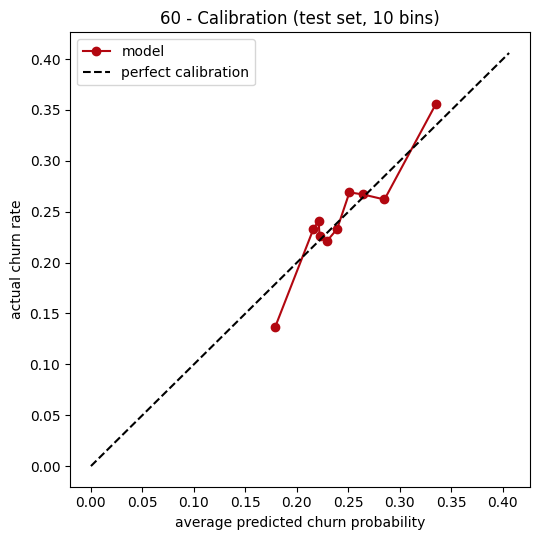


Average predicted 0.244 vs actual 0.245 (gap 0.000)


In [6]:
# ---------- CELL 5: calibration ----------
test_pred["bin"] = pd.qcut(test_pred["churn_probability"].rank(method="first"), 10, labels=False) + 1
calibration = (test_pred.groupby("bin")
               .agg(customers=("churned", "size"),
                    mean_predicted=("churn_probability", "mean"),
                    actual_churn_rate=("churned", "mean"))
               .round(3))
print(calibration)

plt.figure(figsize=(5.5, 5.5))
plt.plot(calibration["mean_predicted"], calibration["actual_churn_rate"], marker="o", color="#b20710", label="model")
top = max(calibration["mean_predicted"].max(), calibration["actual_churn_rate"].max()) + 0.05
plt.plot([0, top], [0, top], "k--", label="perfect calibration")
plt.xlabel("average predicted churn probability"); plt.ylabel("actual churn rate")
plt.title("60 - Calibration (test set, 10 bins)"); plt.legend()
plt.tight_layout(); plt.savefig(FIGURES / "60_calibration.png", bbox_inches="tight"); plt.show()

calibration_gap = abs(test_pred["churn_probability"].mean() - test_pred["churned"].mean())
print(f"\nAverage predicted {test_pred['churn_probability'].mean():.3f} vs actual {test_pred['churned'].mean():.3f} (gap {calibration_gap:.3f})")

In [7]:
# ---------- CELL 6: performance by group ----------
test_groups = test_pred.merge(
    train_table[["customer_id", "plan_name", "acquisition_channel", "customer_segment", "gender"]], on="customer_id")

rows = []
for column in ["plan_name", "acquisition_channel", "customer_segment", "gender"]:
    for group, part in test_groups.groupby(column):
        if len(part) >= 100 and part["churned"].nunique() == 2:
            rows.append({"group_column": column, "group": group, "customers": len(part),
                         "actual_churn_rate": round(part["churned"].mean(), 3),
                         "auc": round(roc_auc_score(part["churned"], part["churn_probability"]), 3)})
by_group = pd.DataFrame(rows).sort_values(["group_column", "auc"])
by_group.to_csv(REPORTS / "model_performance_by_group.csv", index=False)
by_group

,group_column,group,customers,actual_churn_rate,auc
3,acquisition_channel,Affiliate Partner,126,0.278,0.503
8,acquisition_channel,Paid Social,269,0.242,0.529
6,acquisition_channel,Email Campaign,123,0.203,0.547
4,acquisition_channel,App Store,185,0.286,0.552
7,acquisition_channel,Organic Search,332,0.238,0.572
10,acquisition_channel,Referral,197,0.254,0.598
9,acquisition_channel,Partner Bundle (Telecom),122,0.205,0.643
5,acquisition_channel,Direct,102,0.235,0.653
12,customer_segment,Family,349,0.255,0.519
13,customer_segment,Individual,795,0.240,0.573


In [8]:
# ---------- CELL 7: campaign scenarios ----------
CONTACT_COST      = 2.00     # cost of one retention contact (offer, email, call time), in the same currency as the price
SAVE_RATE         = 0.20     # share of would-be churners who stay because we contacted them
MONTHS_OF_VALUE   = 12       # a saved customer is worth this many months of their plan price

active_count = len(value)
avg_price = value["plan_price"].mean()
overall_rate = y_true.mean()

# actual churn rate among the test customers in the riskiest X% (this is the lift measured on Day 10)
scenarios = []
for share in [0.10, 0.20, 0.30, 0.50]:
    cut = np.quantile(score, 1 - share)
    precision = y_true[score >= cut].mean()                  # churn rate among the targeted customers
    contacts = round(active_count * share)

    for label, rate in [("model-targeted", precision), ("random", overall_rate)]:
        churners_reached = contacts * rate
        saves = churners_reached * SAVE_RATE
        gain = saves * avg_price * MONTHS_OF_VALUE
        cost = contacts * CONTACT_COST
        scenarios.append({"campaign_size": f"top {int(share * 100)}%", "targeting": label, "contacts": contacts,
                          "churn_rate_in_group": round(rate, 3), "churners_reached": round(churners_reached),
                          "customers_saved": round(saves), "value_saved": round(gain), "cost": round(cost),
                          "net_value": round(gain - cost)})
scenario_table = pd.DataFrame(scenarios)
scenario_table.to_csv(MODEL_OUT / "campaign_scenarios.csv", index=False)

pivot = scenario_table.pivot(index="campaign_size", columns="targeting", values="net_value")
pivot["extra_from_model"] = pivot["model-targeted"] - pivot["random"]
print(f"Assumptions: contact cost {CONTACT_COST}, save rate {SAVE_RATE:.0%}, {MONTHS_OF_VALUE} months of value, average price {avg_price:.2f}")
pivot

Assumptions: contact cost 2.0, save rate 20%, 12 months of value, average price 13.54


targeting,model-targeted,random,extra_from_model
campaign_size,,,
top 10%,5754,3573,2181
top 20%,9769,7147,2622
top 30%,13690,10720,2970
top 50%,21036,17861,3175


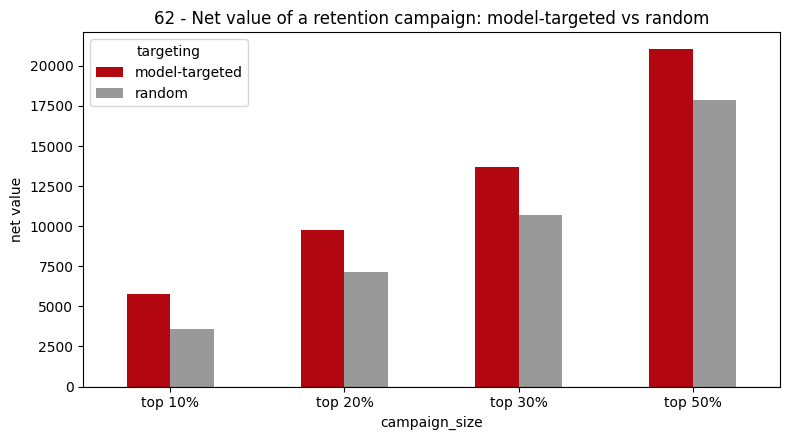

In [9]:
# ---------- CELL 8: chart ----------
pivot[["model-targeted", "random"]].plot(kind="bar", figsize=(8, 4.5), color=["#b20710", "#999999"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("62 - Net value of a retention campaign: model-targeted vs random"); plt.ylabel("net value"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIGURES / "62_campaign_net_value.png", bbox_inches="tight"); plt.show()

In [10]:
# ---------- CELL 9: build reports/model_evaluation_report.md ----------
top20_cut = np.quantile(score, 0.80)
top20_precision = y_true[score >= top20_cut].mean()
top20_recall = y_true[score >= top20_cut].sum() / y_true.sum()
best_extra = pivot["extra_from_model"].idxmax()
weakest = by_group.sort_values("auc").iloc[0]
best_model_row = metrics[metrics["stage"] == "cross-validation after tuning"].iloc[0]["model"]
leaky_auc = metrics[metrics["stage"] == "leakage demonstration"].iloc[0]["auc"]

report = f"""# Churn Model Evaluation Report

*Generated from the project files. Training cutoff {TRAIN_CUTOFF.date()}, scoring date {AS_OF.date()}.*

## 1. What the model does
It estimates, for each customer who is active on {AS_OF.date()}, the probability of churning over a window of about
{HORIZON_MONTHS:.0f} months. Features are measured on a snapshot date using only data available then (no leakage).

## 2. How good is it?
| Measure | Result |
|---|---|
| Model chosen | {best_model_row.replace(' (tuned)', '')} |
| Test AUC | {test_auc:.3f} (95% interval {ci_low:.3f} to {ci_high:.3f}) |
| Average precision | {average_precision_score(y_true, score):.3f} (random guess = {overall_rate:.3f}) |
| Riskiest 20% of customers | {100 * top20_precision:.1f}% churn (average {100 * overall_rate:.1f}%), reaching {100 * top20_recall:.1f}% of all churners |
| Calibration | average predicted {test_pred['churn_probability'].mean():.3f} vs actual {test_pred['churned'].mean():.3f} |

**Plain reading:** the model has a real but modest ability to rank customers by churn risk. It is useful for
choosing *whom to contact first*, not for predicting an individual customer's decision.

## 3. Leakage check
Features computed on the scoring date instead of the cutoff gave an AUC of {leaky_auc:.3f}, higher than the honest
{test_auc:.3f}. The higher number is not a better model; it is a model that has seen the future. The honest figure is the one reported.

## 4. Performance by group
The weakest group on the test set was **{weakest['group']}** ({weakest['group_column']}, n={int(weakest['customers'])}) with AUC {weakest['auc']:.3f}.
Groups of 100-400 customers are noisy; see `reports/model_performance_by_group.csv`.

## 5. Business case (illustrative assumptions)
Contact cost {CONTACT_COST}, save rate {SAVE_RATE:.0%}, {MONTHS_OF_VALUE} months of value per saved customer.
The campaign size with the largest gain over random targeting is **{best_extra}** (details in `data/model_outputs/campaign_scenarios.csv`).
These assumptions are examples and must be replaced with real figures before any decision.

## 6. Customer value
Expected 12-month value is plan price x expected months paid, derived from the churn probability. Total value at risk across
active customers is about {value['value_at_risk_12m'].sum():,.0f} out of {value['max_value_12m'].sum():,.0f}
({100 * value['value_at_risk_12m'].sum() / value['max_value_12m'].sum():.1f}%).
A regression on historical spend was deliberately **not** built: the payments table holds at most 15 payments per customer, so
"future spend" cannot be learned from it.

## 7. Limitations
- Synthetic data with weak signals: AUC of about 0.57 is the honest ceiling here.
- Churn dates only exist from 2025-10-03, so one training snapshot is possible, and no out-of-time test.
- Viewing data covers 12 months only. Payments stop on {dates['last_payment_date'].date()}.
- `auto_renew` is stored as extracted, not as of the snapshot (it may carry slight future information).
- Probabilities are best used as ranks and tiers, not exact chances.

## 8. Recommended next steps
1. Use the High tier (top 20%) as the first retention list, sorted by value at risk (`customer_value.csv`).
2. Run a small controlled test (contact half of the High tier, hold out the other half) to measure the real save rate.
3. Replace the example campaign assumptions with real costs.
4. Re-train when more months of churn data are available.
"""
(REPORTS / "model_evaluation_report.md").write_text(report)
print(report[:1500])

# Churn Model Evaluation Report

*Generated from the project files. Training cutoff 2025-10-02, scoring date 2026-06-30.*

## 1. What the model does
It estimates, for each customer who is active on 2026-06-30, the probability of churning over a window of about
9 months. Features are measured on a snapshot date using only data available then (no leakage).

## 2. How good is it?
| Measure | Result |
|---|---|
| Model chosen | Gradient Boosting |
| Test AUC | 0.568 (95% interval 0.535 to 0.602) |
| Average precision | 0.300 (random guess = 0.245) |
| Riskiest 20% of customers | 31.2% churn (average 24.5%), reaching 25.6% of all churners |
| Calibration | average predicted 0.244 vs actual 0.245 |

**Plain reading:** the model has a real but modest ability to rank customers by churn risk. It is useful for
choosing *whom to contact first*, not for predicting an individual customer's decision.

## 3. Leakage check
Features computed on the scoring date instead of the cutoff gave an AUC of 0.64

In [11]:
# ---------- CELL 10: project log ----------
with open(DOCS / "project_log.md", "a") as f:
    f.write(f"""## Day 12 - Customer value and evaluation
- No CLV regression: payments are capped at 15 per customer. Built a formula-based expected 12-month value instead.
- Test AUC {test_auc:.3f} (95% interval {ci_low:.3f}-{ci_high:.3f}). Riskiest 20% churn at {100 * top20_precision:.1f}% vs {100 * overall_rate:.1f}% average.
- Saved customer_value.csv, campaign_scenarios.csv, model_evaluation_report.md, model_performance_by_group.csv.

""")
print("log updated")

log updated
